In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from src.utils import (PROCESSED_DIR, METRIC_DIR, TABLE_DIR, save_fig, save_table,
                       log_experiment, RANDOM_STATE)
from src.preprocessing import signed_log1p

sns.set_theme(style="whitegrid")

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
with open(METRIC_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)

FEATURES = feature_sets["CORR_FILTERED"]
class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
print("Features:", len(FEATURES))

Mounted at /content/drive
Features: 48


In [2]:
TUNE_FILE = PROCESSED_DIR / "tuning_sample.parquet"
BIG = ["BENIGN", "DoS", "DDoS", "PortScan"]

if TUNE_FILE.exists():
    tune_df = pd.read_parquet(TUNE_FILE)
    print("Loaded the saved tuning sample.")
else:
    train_df = pd.read_parquet(PROCESSED_DIR / "train.parquet")   # NOT test.parquet
    parts = []
    for cls, g in train_df.groupby("Label_Group"):
        if cls in BIG:
            used = g.sample(frac=0.25, random_state=RANDOM_STATE).index   # rows used in the 06a CV sample
            parts.append(g.drop(index=used).sample(frac=0.10, random_state=RANDOM_STATE))
        else:
            parts.append(g)                                               # small classes: keep every row
    tune_df = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    tune_df.to_parquet(TUNE_FILE, index=False)
    del train_df
    print("Built and saved the tuning sample.")

print("Tuning sample rows:", f"{len(tune_df):,}")
print(tune_df["Label_Group"].value_counts())

X_tune = pd.DataFrame(signed_log1p(tune_df[FEATURES].values), columns=FEATURES).astype("float32")
y_tune = tune_df["Label_Group"].map(label_mapping).values

Built and saved the tuning sample.
Tuning sample rows: 159,713
Label_Group
BENIGN          124335
DoS              11624
DDoS              7681
PortScan          5442
FTP-Patator       4745
SSH-Patator       2575
Web Attack        1715
Bot               1558
Infiltration        29
Heartbleed           9
Name: count, dtype: int64


In [3]:
import warnings
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

USE_SMOTE = True        # set False to tune without SMOTE
SMOTE_TARGET = 2_000
N_ITER = 10
BEST_JSON = METRIC_DIR / "06c_best_params.json"

def smote_strategy(y):
    """Top up every class that has fewer than SMOTE_TARGET rows (computed inside each training fold)."""
    return {c: SMOTE_TARGET for c, n in Counter(y).items() if n < SMOTE_TARGET}

def build_pipeline(model, use_smote=USE_SMOTE):
    steps = []
    if use_smote:
        steps.append(("smote", SMOTE(sampling_strategy=smote_strategy, k_neighbors=5,
                                     random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

SEARCH = {
    "XGBoost": (
        XGBClassifier(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, verbosity=0),
        {"model__n_estimators": [100, 200, 300],
         "model__max_depth": [4, 6, 8, 10],
         "model__learning_rate": [0.05, 0.1, 0.2, 0.3],
         "model__subsample": [0.7, 0.85, 1.0],
         "model__colsample_bytree": [0.6, 0.8, 1.0],
         "model__min_child_weight": [1, 3, 5]}),
    "Random Forest": (
        RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 150, 200],
         "model__max_depth": [12, 20, 30, None],
         "model__min_samples_split": [2, 5, 10],
         "model__min_samples_leaf": [1, 2, 4],
         "model__max_features": ["sqrt", "log2"]}),
}

def clean(v):
    return v.item() if hasattr(v, "item") else v

def run_tuning(name):
    out_csv = TABLE_DIR / f"06c_tuning_{name.replace(' ', '_')}.csv"
    if out_csv.exists():
        print(f"[skip] {name}: tuning already saved ->", out_csv.name)
        return pd.read_csv(out_csv)
    est, space = SEARCH[name]
    rs = RandomizedSearchCV(
        build_pipeline(est), space, n_iter=N_ITER, scoring="f1_macro",
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, n_jobs=1, refit=False, verbose=2, error_score="raise")
    t0 = time.time()
    rs.fit(X_tune, y_tune)
    minutes = (time.time() - t0) / 60

    res = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
    cols = ["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time"] + \
           [c for c in res.columns if c.startswith("param_")]
    res[cols].to_csv(out_csv, index=False)

    best = {k.replace("model__", ""): clean(v) for k, v in rs.best_params_.items()}
    allbest = json.load(open(BEST_JSON)) if BEST_JSON.exists() else {}
    allbest[name] = best
    json.dump(allbest, open(BEST_JSON, "w"), indent=2)

    log_experiment(
        experiment_id=f"EXP-05_tuning_{name}".replace(" ", "_"),
        task="Experiment B: multi-class (Label_Group)", model=name,
        features=f"CORR_FILTERED ({len(FEATURES)}), signed-log transformed",
        preprocessing="SMOTE inside training folds" if USE_SMOTE else "none",
        hyperparameters=best, split="3-fold CV on the tuning sample (inside the training set)",
        metrics={"best_macro_f1_cv3": round(float(rs.best_score_), 4)},
        notes=f"RandomizedSearchCV, {N_ITER} settings, {minutes:.0f} min",
    )
    print(f"\nBest macro-F1 (3-fold): {rs.best_score_:.4f} | took {minutes:.1f} min")
    print("Best settings:", best)
    return res[cols]

print("Ready. USE_SMOTE =", USE_SMOTE)

Ready. USE_SMOTE = True


In [4]:
xgb_tuning = run_tuning("XGBoost")
print(xgb_tuning.head(5).to_string(index=False))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.2, model__max_depth=6, model__min_child_weight=5, model__n_estimators=100, model__subsample=0.85; total time=  32.8s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.2, model__max_depth=6, model__min_child_weight=5, model__n_estimators=100, model__subsample=0.85; total time=  32.3s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.2, model__max_depth=6, model__min_child_weight=5, model__n_estimators=100, model__subsample=0.85; total time=  31.8s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.3, model__max_depth=10, model__min_child_weight=5, model__n_estimators=200, model__subsample=1.0; total time=  50.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.3, model__max_depth=10, model__min_child_weight=5, model__n_estimators=200, model__subsample=1.0; total time=  57.3s
[CV] END model__colsample_bytree=0.8, model__lear

In [8]:
rf_tuning = run_tuning("Random Forest")
print(rf_tuning.head(5).to_string(index=False))

[skip] Random Forest: tuning already saved -> 06c_tuning_Random_Forest.csv
 rank_test_score  mean_test_score  std_test_score  mean_fit_time  param_model__n_estimators  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  param_model__max_depth
               1         0.971217        0.015381      32.244354                        100                               5                              1                      sqrt                    30.0
               2         0.970869        0.014906      41.233819                        150                               5                              1                      log2                    30.0
               3         0.970807        0.015103      27.266387                        100                               5                              1                      log2                    30.0
               4         0.970495        0.015327      32.332678                        100              

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_fscore_support)

cv_df = pd.read_parquet(PROCESSED_DIR / "cv_sample.parquet")
y_cv_multi = cv_df["Label_Group"].map(label_mapping).values
y_cv_bin = cv_df["Binary"].values
X_cv = pd.DataFrame(signed_log1p(cv_df[FEATURES].values), columns=FEATURES).astype("float32")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_cv, cv_df["Label_Group"]))      # identical to 06a and 06b
print("Fold quiz sizes:", [len(va) for _, va in folds])

best_params = json.load(open(BEST_JSON))
print(json.dumps(best_params, indent=2))

TUNED_CSV = TABLE_DIR / "06c_tuned_cv_fold_metrics.csv"

def make_tuned(name):
    p = dict(best_params[name])
    if name == "XGBoost":
        return XGBClassifier(**p, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, verbosity=0)
    return RandomForestClassifier(**p, n_jobs=-1, random_state=RANDOM_STATE)

def run_tuned_cv(task, name):
    rows = pd.read_csv(TUNED_CSV).to_dict("records") if TUNED_CSV.exists() else []
    if any(r["model"] == name and r["task"] == task for r in rows):
        print(f"[skip] {name} / {task} (already saved)")
        return
    y_all = y_cv_bin if task == "binary" else y_cv_multi
    use_smote = (task == "multiclass") and USE_SMOTE        # binary: original data
    oof = np.zeros(len(y_all), dtype=np.int8)

    for k, (tr, va) in enumerate(folds, 1):
        model = build_pipeline(make_tuned(name), use_smote=use_smote)
        t0 = time.time()
        model.fit(X_cv.iloc[tr], y_all[tr])
        fit_s = time.time() - t0
        y_v = y_all[va]
        if task == "binary":
            proba = model.predict_proba(X_cv.iloc[va])
            pred = proba.argmax(axis=1)
            m = {"accuracy": accuracy_score(y_v, pred),
                 "precision": precision_score(y_v, pred, zero_division=0),
                 "recall": recall_score(y_v, pred, zero_division=0),
                 "f1": f1_score(y_v, pred, zero_division=0),
                 "roc_auc": roc_auc_score(y_v, proba[:, 1]),
                 "pr_auc": average_precision_score(y_v, proba[:, 1])}
            key = "f1"
        else:
            pred = model.predict(X_cv.iloc[va])
            present = np.unique(y_v)
            m = {"accuracy": accuracy_score(y_v, pred),
                 "macro_f1": f1_score(y_v, pred, labels=present, average="macro", zero_division=0),
                 "weighted_f1": f1_score(y_v, pred, average="weighted", zero_division=0)}
            key = "macro_f1"
        oof[va] = pred
        rows.append({"model": name, "task": task, "fold": k, "train_seconds": round(fit_s, 1), **m})
        print(f"{name:14s} {task:10s} fold {k}/5 | fit {fit_s:6.1f}s | {key} {m[key]:.4f}")

    np.save(METRIC_DIR / f"06c_oof_tuned_{name.replace(' ', '_')}_{task}.npy", oof)
    pd.DataFrame(rows).to_csv(TUNED_CSV, index=False)
    mine = pd.DataFrame([r for r in rows if r["model"] == name and r["task"] == task])
    log_experiment(
        experiment_id=f"EXP-06_tuned_cv_{task}_{name}".replace(" ", "_"),
        task="Experiment A: binary" if task == "binary" else "Experiment B: multi-class (Label_Group)",
        model=f"{name} (tuned)", features=f"CORR_FILTERED ({len(FEATURES)}), signed-log transformed",
        preprocessing="SMOTE inside training folds" if use_smote else "original data (no resampling)",
        hyperparameters=best_params[name], split="stratified 5-fold CV on the CV sample",
        metrics={k2: round(float(mine[k2].mean()), 4) for k2 in m.keys()},
        notes="same folds as 06a/06b",
    )

print("Ready.")

Fold quiz sizes: [101514, 101514, 101514, 101514, 101514]
{
  "XGBoost": {
    "subsample": 1.0,
    "n_estimators": 200,
    "min_child_weight": 5,
    "max_depth": 6,
    "learning_rate": 0.2,
    "colsample_bytree": 1.0
  },
  "Random Forest": {
    "n_estimators": 100,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "max_depth": 30
  }
}
Ready.


In [10]:
run_tuned_cv("multiclass", "XGBoost")
run_tuned_cv("multiclass", "Random Forest")
run_tuned_cv("binary", "XGBoost")
print("All done.")

XGBoost        multiclass fold 1/5 | fit  196.2s | macro_f1 0.9493
XGBoost        multiclass fold 2/5 | fit  194.6s | macro_f1 0.9898
XGBoost        multiclass fold 3/5 | fit  197.1s | macro_f1 0.9829
XGBoost        multiclass fold 4/5 | fit  191.7s | macro_f1 0.9722
XGBoost        multiclass fold 5/5 | fit  194.3s | macro_f1 0.9757
[logged experiment] EXP-06_tuned_cv_multiclass_XGBoost
Random Forest  multiclass fold 1/5 | fit  141.4s | macro_f1 0.9604
Random Forest  multiclass fold 2/5 | fit  148.4s | macro_f1 0.9881
Random Forest  multiclass fold 3/5 | fit  142.7s | macro_f1 0.9680
Random Forest  multiclass fold 4/5 | fit  144.0s | macro_f1 0.9697
Random Forest  multiclass fold 5/5 | fit  148.9s | macro_f1 0.9470
[logged experiment] EXP-06_tuned_cv_multiclass_Random_Forest
XGBoost        binary     fold 1/5 | fit   25.2s | f1 0.9970
XGBoost        binary     fold 2/5 | fit   21.6s | f1 0.9966
XGBoost        binary     fold 3/5 | fit   24.8s | f1 0.9972
XGBoost        binary     fold 

MULTI-CLASS: baseline vs optimized

                configuration macro-F1 (mean ± std)  pooled macro-F1  Bot F1  Infiltration recall  Heartbleed F1  false-alarm rate (%)
  XGBoost baseline (no SMOTE)       0.9592 ± 0.0251           0.9612   0.922                0.724          0.889                 0.117
   XGBoost + SMOTE (defaults)       0.9745 ± 0.0118           0.9746   0.929                0.897          1.000                 0.107
      XGBoost + SMOTE (tuned)       0.9740 ± 0.0154           0.9754   0.931                0.862          0.947                 0.106
 Random Forest baseline (06a)       0.9653 ± 0.0186           0.9661   0.909                0.724          0.941                 0.091
Random Forest + SMOTE (tuned)       0.9666 ± 0.0150           0.9673   0.915                0.759          0.941                 0.092
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/06c_baseline_vs_tuned_multiclass.csv

BINARY: baseline vs optimized

            

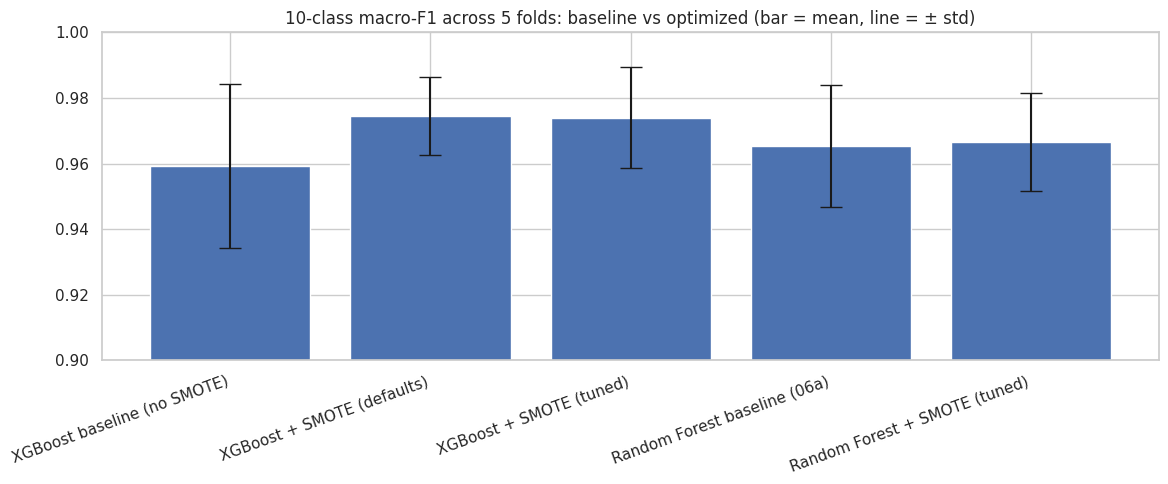

In [11]:
fa = pd.read_csv(TUNED_CSV)
f6a = pd.read_csv(TABLE_DIR / "06a_cv_fold_metrics.csv")
f6b = pd.read_csv(TABLE_DIR / "06b_imbalance_fold_metrics.csv")

def pm(s, nd=4):
    return f"{s.mean():.{nd}f} ± {s.std():.{nd}f}"

configs = {   # name: (per-fold macro-F1, out-of-fold prediction file)
    "XGBoost baseline (no SMOTE)": (f6b[f6b.strategy == "original"]["macro_f1"], "06b_oof_original.npy"),
    "XGBoost + SMOTE (defaults)": (f6b[f6b.strategy == "smote"]["macro_f1"], "06b_oof_smote.npy"),
    "XGBoost + SMOTE (tuned)": (fa[(fa.model == "XGBoost") & (fa.task == "multiclass")]["macro_f1"],
                                "06c_oof_tuned_XGBoost_multiclass.npy"),
    "Random Forest baseline (06a)": (f6a[(f6a.model == "Random Forest") & (f6a.task == "multiclass")]["macro_f1"],
                                     "06a_oof_Random_Forest_multiclass.npy"),
    "Random Forest + SMOTE (tuned)": (fa[(fa.model == "Random Forest") & (fa.task == "multiclass")]["macro_f1"],
                                      "06c_oof_tuned_Random_Forest_multiclass.npy"),
}

rows = []
for label, (scores, oof_file) in configs.items():
    oof = np.load(METRIC_DIR / oof_file)
    p, r, f, s = precision_recall_fscore_support(
        y_cv_multi, oof, labels=list(range(len(class_names))), zero_division=0)
    f1c, rec = dict(zip(class_names, f)), dict(zip(class_names, r))
    rows.append({"configuration": label, "macro-F1 (mean ± std)": pm(scores),
                 "pooled macro-F1": round(float(np.mean(f)), 4),
                 "Bot F1": round(f1c["Bot"], 3),
                 "Infiltration recall": round(rec["Infiltration"], 3),
                 "Heartbleed F1": round(f1c["Heartbleed"], 3),
                 "false-alarm rate (%)": round((1 - rec["BENIGN"]) * 100, 3)})
summary = pd.DataFrame(rows)
print("MULTI-CLASS: baseline vs optimized\n")
print(summary.to_string(index=False))
save_table(summary, "06c_baseline_vs_tuned_multiclass", index=False)

# Binary
b_base = f6a[(f6a.model == "XGBoost") & (f6a.task == "binary")]
b_tuned = fa[(fa.model == "XGBoost") & (fa.task == "binary")]
bin_cmp = pd.DataFrame([
    {"model": "XGBoost baseline (06a)", "F1": pm(b_base["f1"]), "Recall": pm(b_base["recall"]),
     "Precision": pm(b_base["precision"]), "PR-AUC": pm(b_base["pr_auc"])},
    {"model": "XGBoost tuned", "F1": pm(b_tuned["f1"]), "Recall": pm(b_tuned["recall"]),
     "Precision": pm(b_tuned["precision"]), "PR-AUC": pm(b_tuned["pr_auc"])}])
print("\nBINARY: baseline vs optimized\n")
print(bin_cmp.to_string(index=False))
save_table(bin_cmp, "06c_baseline_vs_tuned_binary", index=False)

# Chart: macro-F1 per fold (bar = mean, line = std)
labels = list(configs.keys())
means = [configs[l][0].mean() for l in labels]
stds = [configs[l][0].std() for l in labels]
plt.figure(figsize=(12, 5))
plt.bar(range(len(labels)), means, yerr=stds, capsize=8, color="#4C72B0")
plt.xticks(range(len(labels)), labels, rotation=20, ha="right")
plt.ylim(0.9, 1.0)
plt.title("10-class macro-F1 across 5 folds: baseline vs optimized (bar = mean, line = ± std)")
save_fig("06c_baseline_vs_tuned")
plt.show()